<a href="https://colab.research.google.com/github/bittu-quant-ai/bittu-quant-ai/blob/main/Little_Animation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving IMG-20261102-WA0003.jpg to IMG-20261102-WA0003.jpg


In [ ]:
!pip install pillow numpy

Using image: IMG-20261102-WA0003.jpg
Generating frames...
  10/70 frames done
  20/70 frames done
  30/70 frames done
  40/70 frames done
  50/70 frames done
  60/70 frames done
  70/70 frames done
Creating GIF...
Done! Saved as: classical_hand_sketch.gif


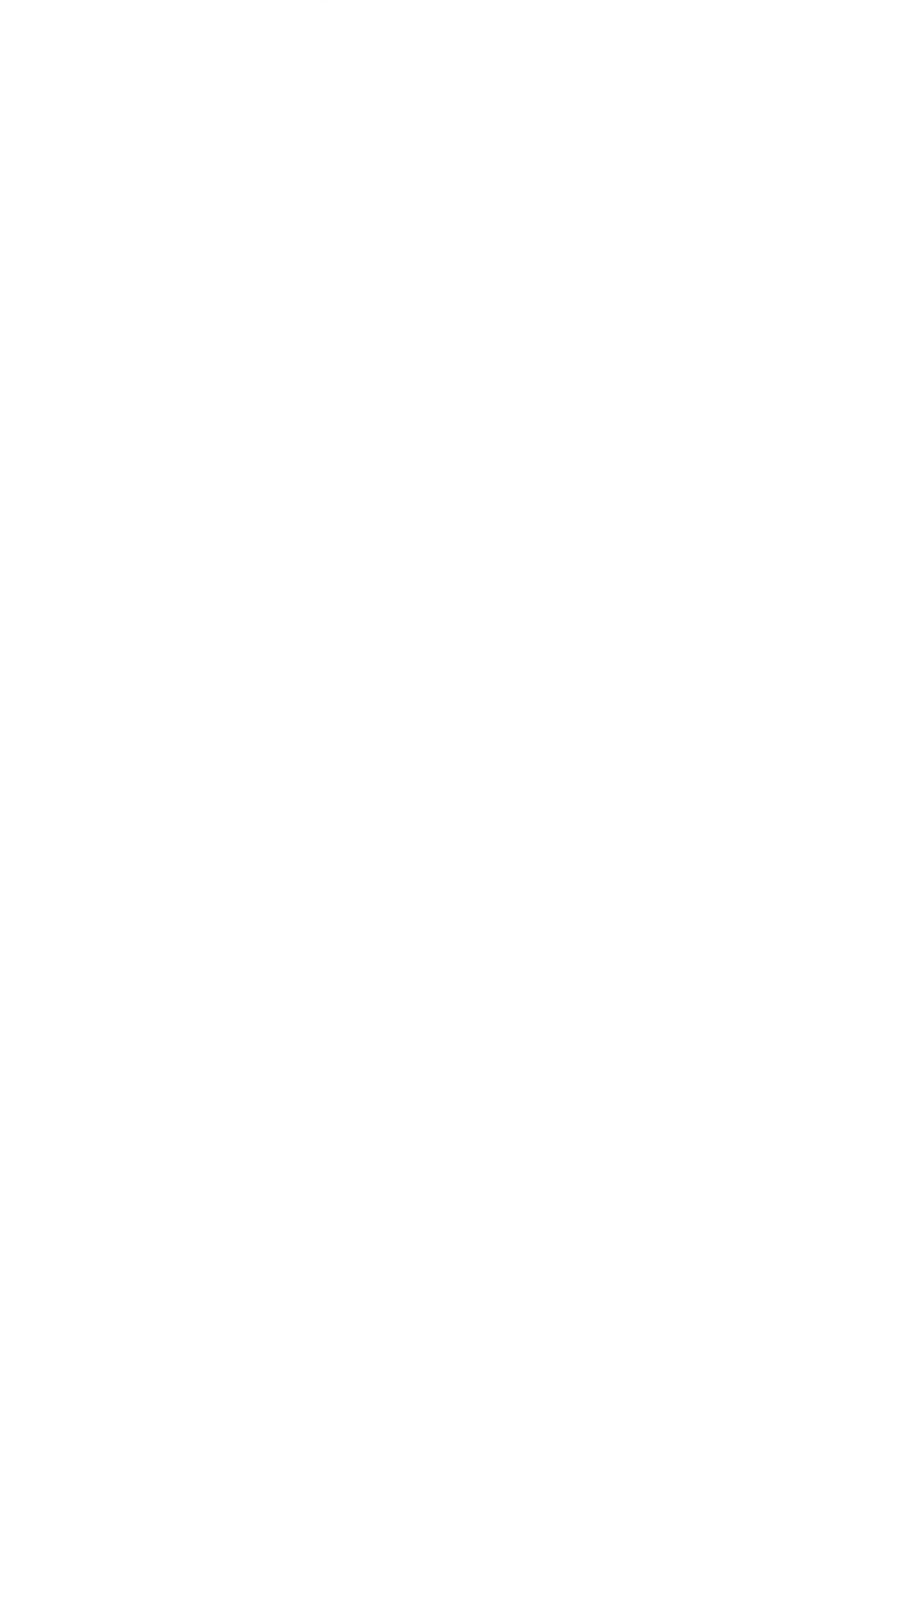

In [ ]:

from PIL import Image, ImageDraw, ImageFilter, ImageOps, ImageEnhance
import numpy as np
import os
from IPython.display import Image as IPImage, display
import glob

def create_pencil_sketch(img):
    """Convert image to pencil-sketch style"""
    gray = img.convert("L")
    inverted = ImageOps.invert(gray)
    blur = inverted.filter(ImageFilter.GaussianBlur(radius=8))

    gray_arr = np.array(gray).astype(np.float32)
    blur_arr = np.array(blur).astype(np.float32)

    # Color dodge blend
    sketch = np.clip(gray_arr * 255.0 / (255.0 - blur_arr + 1e-5), 0, 255)
    sketch = Image.fromarray(sketch.astype(np.uint8))

    enhancer = ImageEnhance.Contrast(sketch)
    sketch = enhancer.enhance(1.5)
    return sketch.convert("RGB")

def create_hand_sketch_animation(
    input_path,
    output_gif="hand_sketch.gif",
    frames=60,
    direction="top_to_bottom"
):
    # Load image
    original = Image.open(input_path).convert("RGB")
    w, h = original.size

    # Create sketch version
    sketch = create_pencil_sketch(original)
    white = Image.new("RGB", (w, h), (255, 255, 255))

    os.makedirs("sketch_frames", exist_ok=True)

    print("Generating frames...")
    for i in range(frames):
        progress = (i + 1) / frames
        mask = Image.new("L", (w, h), 0)
        draw = ImageDraw.Draw(mask)

        if direction == "top_to_bottom":
            reveal_height = int(h * progress)
            draw.rectangle([0, 0, w, reveal_height], fill=255)
            mask = mask.filter(ImageFilter.GaussianBlur(radius=15))
        else:  # left_to_right
            reveal_width = int(w * progress)
            draw.rectangle([0, 0, reveal_width, h], fill=255)
            mask = mask.filter(ImageFilter.GaussianBlur(radius=15))

        frame = Image.composite(sketch, white, mask)
        frame.save(f"sketch_frames/frame_{i:04d}.png")

        if (i+1) % 10 == 0:
            print(f"  {i+1}/{frames} frames done")

    # Create GIF using PIL (no ffmpeg needed)
    print("Creating GIF...")
    frame_files = sorted(glob.glob("sketch_frames/frame_*.png"))
    frames_list = [Image.open(f) for f in frame_files]

    frames_list[0].save(
        output_gif,
        save_all=True,
        append_images=frames_list[1:],
        duration=80,          # milliseconds per frame
        loop=0
    )

    print(f"Done! Saved as: {output_gif}")
    return output_gif

# ====================== RUN ======================
# Automatically use the uploaded file
image_name = list(uploaded.keys())[0]
print(f"Using image: {image_name}")

gif_path = create_hand_sketch_animation(
    input_path=image_name,
    output_gif="classical_hand_sketch.gif",
    frames=70,                    # Increase for smoother animation
    direction="top_to_bottom"     # or "left_to_right"
)

# Display the animation
display(IPImage(gif_path))

In [ ]:

from google.colab import files
files.download("classical_hand_sketch.gif")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>